# Exploración de la demanda horaria del SIN

Este notebook responde cuatro preguntas antes de modelar: cómo cambia la demanda a lo largo del día, de la semana y del año, y cuánto pesa un festivo. Usa la serie procesada de `DemaCome` / `Sistema` (solo días completos; ver `docs/data_notes.md`).

Para regenerarlo con datos nuevos:

```
uv sync --group notebook
uv run python -m demand_forecast.cli ingest
uv run jupyter execute notebooks/01_exploration.ipynb --inplace
```

En Windows hay que definir antes `PYTHONUTF8=1` (en PowerShell, `$env:PYTHONUTF8 = "1"`), porque `jupyter execute` lee el notebook con la codificación del sistema. También se puede abrir en VS Code y ejecutar todas las celdas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from demand_forecast import config
from demand_forecast.data import store
from demand_forecast.daytypes import SATURDAY, SUNDAY_OR_HOLIDAY, WORKDAY, day_types

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CONTEXT = "#c3c2b7"
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE = "#fcfcfb"

plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.titlelocation": "left",
        "axes.titlepad": 12,
        "axes.labelcolor": INK_SECONDARY,
        "axes.edgecolor": CONTEXT,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 1,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "ytick.left": False,
        "lines.linewidth": 2,
        "lines.solid_capstyle": "round",
        "legend.frameon": False,
    }
)


def label_line_end(ax, x, y, text):
    """Name a line at its last point, in text ink (the line carries the color)."""
    ax.annotate(
        text, (x, y), xytext=(8, 0), textcoords="offset points", va="center", color=INK_SECONDARY
    )

In [2]:
demand = store.load_series(config.DEMAND.name, ROOT / config.DATA_DIR) / 1e6  # GWh por hora
daily = demand.resample("D").sum()  # GWh por día
types = day_types(daily.index)

last_day = daily.index.max()
last_year = daily.index > last_day - pd.DateOffset(years=1)
last_three_years = daily.index > last_day - pd.DateOffset(years=3)

print(f"Serie: {daily.index.min():%Y-%m-%d} a {last_day:%Y-%m-%d} ({len(daily):,} días completos)")
print(f"Último año: desde {daily.index[last_year].min():%Y-%m-%d}")

Serie: 2000-01-01 a 2026-11-06 (9,807 días completos)
Último año: desde 2025-11-07


## 1. Tendencia de largo plazo

Antes de mirar la estacionalidad conviene saber cuánto ha cambiado el nivel, porque de eso depende cuánta historia sirve para entrenar.

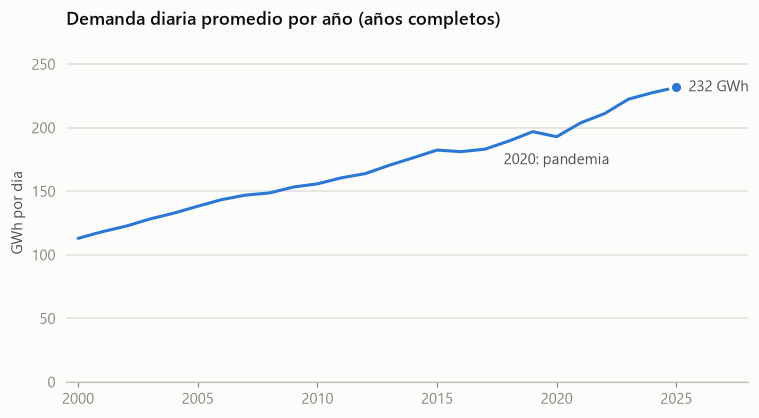

2000: 113 GWh/día  ->  2025: 232 GWh/día (x2.05)
Crecimiento medio de los últimos 5 años: 3.7 % anual


In [3]:
complete_years = daily.groupby(daily.index.year).filter(lambda year: len(year) >= 365)
by_year = complete_years.groupby(complete_years.index.year).mean()

fig, ax = plt.subplots()
ax.plot(by_year.index, by_year, color=BLUE)
ax.plot(
    by_year.index[-1],
    by_year.iloc[-1],
    "o",
    color=BLUE,
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
label_line_end(ax, by_year.index[-1], by_year.iloc[-1], f"{by_year.iloc[-1]:.0f} GWh")
ax.annotate(
    "2020: pandemia",
    (2020, by_year.loc[2020]),
    xytext=(0, -18),
    textcoords="offset points",
    ha="center",
    color=INK_SECONDARY,
)
ax.set_ylim(0, by_year.max() * 1.15)
ax.set_xlim(by_year.index[0] - 0.5, by_year.index[-1] + 3)
ax.set_ylabel("GWh por día")
ax.set_title("Demanda diaria promedio por año (años completos)")
plt.show()

growth = by_year.iloc[-1] / by_year.iloc[0]
print(
    f"{by_year.index[0]}: {by_year.iloc[0]:.0f} GWh/día  ->  {by_year.index[-1]}: {by_year.iloc[-1]:.0f} GWh/día (x{growth:.2f})"
)
print(
    f"Crecimiento medio de los últimos 5 años: {((by_year.iloc[-1] / by_year.iloc[-6]) ** (1 / 5) - 1) * 100:.1f} % anual"
)

## 2. Estacionalidad diaria

Perfil horario promedio del último año, por tipo de día. La hora 0 es el intervalo 00:00–01:00, hora de Bogotá.

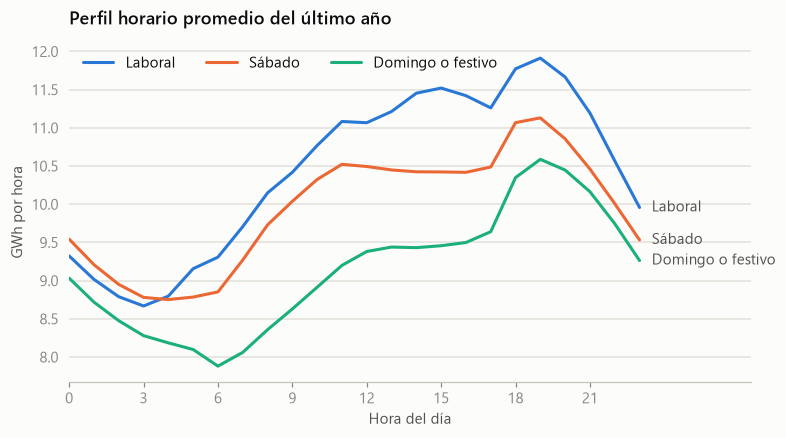

,hora mínima,hora pico,pico / mínimo
workday,3,19,1.37
saturday,4,19,1.27
sunday_or_holiday,6,19,1.34


In [4]:
recent = demand[demand.index.normalize().isin(daily.index[last_year])]
recent_types = types.reindex(recent.index.normalize()).to_numpy()
profile = recent.groupby([recent.index.hour, recent_types]).mean().unstack()

series = [
    (WORKDAY, "Laboral", BLUE),
    (SATURDAY, "Sábado", ORANGE),
    (SUNDAY_OR_HOLIDAY, "Domingo o festivo", AQUA),
]
fig, ax = plt.subplots()
for key, name, color in series:
    ax.plot(profile.index, profile[key], color=color, label=name)
    label_line_end(ax, 23, profile[key].iloc[-1], name)
ax.set_xticks(range(0, 24, 3))
ax.set_xlim(0, 27.5)
ax.set_xlabel("Hora del día")
ax.set_ylabel("GWh por hora")
ax.set_title("Perfil horario promedio del último año")
ax.legend(loc="upper left", ncols=3, bbox_to_anchor=(0, 1.0))
plt.show()

summary = pd.DataFrame(
    {
        "hora mínima": profile.idxmin(),
        "hora pico": profile.idxmax(),
        "pico / mínimo": (profile.max() / profile.min()).round(2),
    }
).loc[[key for key, _, _ in series]]
summary

## 3. Estacionalidad semanal

Energía diaria promedio por día de la semana en el último año. Se excluyen los festivos para ver solo el efecto del día de la semana.

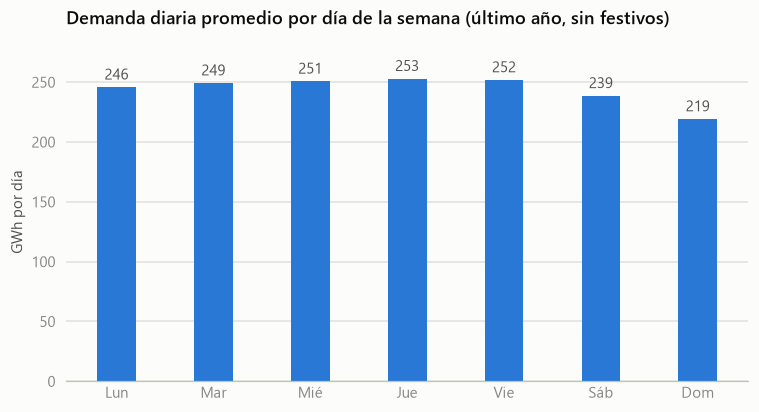

Sábado: -4.6 % frente al promedio de lunes a viernes
Domingo: -12.3 %


In [5]:
not_holiday = (
    (types == WORKDAY)
    | (types == SATURDAY)
    | ((types == SUNDAY_OR_HOLIDAY) & (daily.index.dayofweek == 6))
)
week = daily[last_year & not_holiday]
by_weekday = week.groupby(week.index.dayofweek).mean()
names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, ax = plt.subplots()
bars = ax.bar(names, by_weekday, width=0.4, color=BLUE)
ax.bar_label(bars, fmt="{:.0f}", padding=3, color=INK_SECONDARY)
ax.set_ylim(0, by_weekday.max() * 1.12)
ax.set_ylabel("GWh por día")
ax.set_title("Demanda diaria promedio por día de la semana (último año, sin festivos)")
ax.tick_params(axis="x", length=0)
plt.show()

workday_level = by_weekday.iloc[:5].mean()
print(
    f"Sábado: {(by_weekday.iloc[5] / workday_level - 1) * 100:+.1f} % frente al promedio de lunes a viernes"
)
print(f"Domingo: {(by_weekday.iloc[6] / workday_level - 1) * 100:+.1f} %")

## 4. Estacionalidad anual

La demanda crece cerca de un 4 % al año, así que comparar cada mes con el promedio de su año mezclaría estacionalidad y tendencia. Aquí cada día se divide por la media móvil centrada de 365 días y luego se promedia por mes. Se usan los últimos cinco años con la media móvil completa.

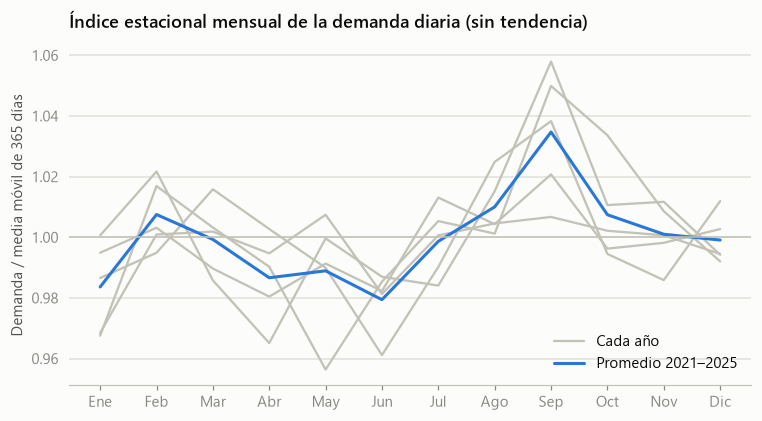

Mes más bajo: Jun (-2.1 %)
Mes más alto: Sep (+3.5 %)


In [6]:
detrended = (daily / daily.rolling(365, center=True).mean()).dropna()
index = detrended.groupby([detrended.index.month, detrended.index.year]).mean().unstack()
years = index.columns[index.notna().all()][-5:]
index = index[years]
average = index.mean(axis=1)
months = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots()
for position, year in enumerate(years):
    ax.plot(
        months,
        index[year],
        color=CONTEXT,
        linewidth=1.5,
        label="Cada año" if position == 0 else None,
    )
ax.plot(months, average, color=BLUE, label=f"Promedio {years[0]}–{years[-1]}")
ax.axhline(1, color=CONTEXT, linewidth=1)
ax.set_ylabel("Demanda / media móvil de 365 días")
ax.set_title("Índice estacional mensual de la demanda diaria (sin tendencia)")
ax.legend(loc="lower right")
plt.show()

print(f"Mes más bajo: {months[average.idxmin() - 1]} ({(average.min() - 1) * 100:+.1f} %)")
print(f"Mes más alto: {months[average.idxmax() - 1]} ({(average.max() - 1) * 100:+.1f} %)")

## 5. Efecto de los festivos

Primero el perfil horario: un festivo que cae entre lunes y viernes, comparado con un día laboral y con un domingo (últimos tres años).

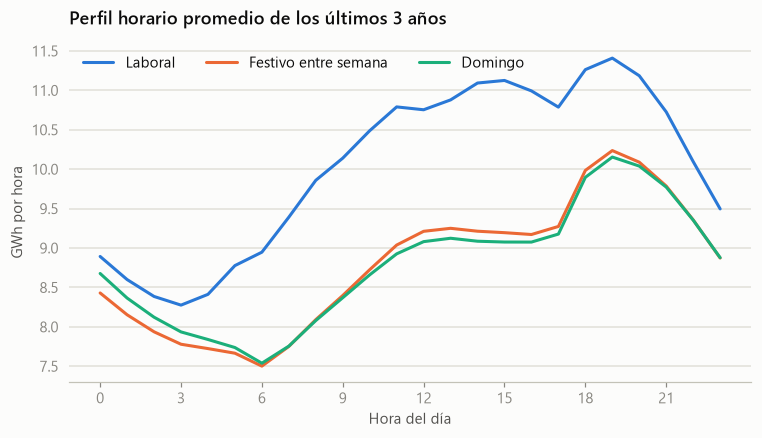

Festivos entre semana en la ventana: 51


In [7]:
weekday_holiday = (types == SUNDAY_OR_HOLIDAY) & (daily.index.dayofweek < 5)
sunday = daily.index.dayofweek == 6
groups = pd.Series("otro", index=daily.index)
groups[types == WORKDAY] = "Laboral"
groups[sunday] = "Domingo"
groups[weekday_holiday] = "Festivo entre semana"

window = demand[demand.index.normalize().isin(daily.index[last_three_years])]
window_groups = groups.reindex(window.index.normalize()).to_numpy()
holiday_profile = window.groupby([window.index.hour, window_groups]).mean().unstack()

series = [("Laboral", BLUE), ("Festivo entre semana", ORANGE), ("Domingo", AQUA)]
fig, ax = plt.subplots()
for name, color in series:
    ax.plot(holiday_profile.index, holiday_profile[name], color=color, label=name)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hora del día")
ax.set_ylabel("GWh por hora")
ax.set_title("Perfil horario promedio de los últimos 3 años")
ax.legend(loc="upper left", ncols=3)
plt.show()

print(f"Festivos entre semana en la ventana: {int((weekday_holiday & last_three_years).sum())}")

Ahora el tamaño del efecto en la energía del día. Cada día se compara con un día "normal": la mediana de los días laborales del mismo día de la semana en las cuatro semanas anteriores y posteriores. También se miden la víspera y el día siguiente al festivo, cuando son laborales.

In [8]:
normal = daily.where(types == WORKDAY)
reference = pd.concat([normal.shift(7 * k) for k in (-4, -3, -2, -1, 1, 2, 3, 4)], axis=1).median(
    axis=1
)
ratio = (daily / reference - 1) * 100

holiday = weekday_holiday & last_three_years
is_workday = (types == WORKDAY).to_numpy()
cases = {
    "Víspera laboral de un festivo": pd.Series(holiday, index=daily.index)
    .shift(-1, fill_value=False)
    .to_numpy()
    & is_workday,
    "Festivo entre semana": holiday,
    "Día laboral siguiente a un festivo": pd.Series(holiday, index=daily.index)
    .shift(1, fill_value=False)
    .to_numpy()
    & is_workday,
}
effect = pd.DataFrame(
    {
        "días": {name: int(mask.sum()) for name, mask in cases.items()},
        "diferencia media (%)": {name: ratio[mask].mean().round(1) for name, mask in cases.items()},
        "mínima (%)": {name: ratio[mask].min().round(1) for name, mask in cases.items()},
        "máxima (%)": {name: ratio[mask].max().round(1) for name, mask in cases.items()},
    }
)
effect

,días,diferencia media (%),mínima (%),máxima (%)
Víspera laboral de un festivo,14,-4.1,-16.7,1.4
Festivo entre semana,51,-12.4,-26.6,-5.9
Día laboral siguiente a un festivo,42,-2.7,-14.2,3.8


## 6. Horas marcadas como atípicas

La tabla procesada marca las horas que se desvían más de un 35 % de la mediana de esa misma hora en los 28 días anteriores (`docs/decisions.md`). No se borran: aquí se ve cuántas son y cuándo ocurren.

In [9]:
table = store.read_table(store.processed_dir(config.DEMAND.name, ROOT / config.DATA_DIR))
flagged = table[table["anomaly"]].copy()
flagged["día"] = flagged["timestamp"].dt.normalize()
flagged["tipo"] = types.reindex(flagged["día"]).to_numpy()

print(
    f"Horas marcadas: {len(flagged)} de {len(table):,} ({len(flagged) / len(table):.4%}), en {flagged['día'].nunique()} días"
)
print(f"En los últimos 12 meses: {int((flagged['día'] > last_day - pd.DateOffset(years=1)).sum())}")
flagged.groupby(flagged["día"].dt.date).agg(
    horas=("value", "size"), tipo=("tipo", "first")
).sort_values("horas", ascending=False).head(10)

Horas marcadas: 111 de 235,368 (0.0472%), en 33 días
En los últimos 12 meses: 0


,horas,tipo
día,,
2006-01-01,11,sunday_or_holiday
2007-12-25,8,sunday_or_holiday
2005-12-25,8,sunday_or_holiday
2009-01-01,7,sunday_or_holiday
2001-01-01,7,sunday_or_holiday
2013-01-01,6,sunday_or_holiday
2008-12-25,6,sunday_or_holiday
2012-01-01,5,sunday_or_holiday
2011-01-01,5,sunday_or_holiday


## 7. Qué implica para el modelo

Con datos hasta el 2026-11-06:

- **El nivel cambia rápido.** La demanda diaria se duplicó entre 2000 y 2025 y creció cerca de un 3,7 % anual en los últimos cinco años. Las features deben cargar el nivel reciente (rezagos y medias móviles), y entrenar con toda la historia sin normalizar mezclaría niveles muy distintos.
- **La hora manda, y su efecto depende del tipo de día.** El mínimo está entre las 03:00 y las 04:00 y el pico entre las 19:00 y las 20:00, con una relación pico/mínimo de 1,37 en días laborales. El sábado no tiene la rampa de la tarde y el domingo arranca más tarde, así que hora y tipo de día deben poder interactuar.
- **De lunes a viernes la energía diaria casi no cambia** (246 a 253 GWh). El sábado baja un 4,6 % y el domingo un 12,3 %.
- **La estacionalidad anual es pequeña:** unos ±3 % una vez quitada la tendencia, con máximo en septiembre y mínimo en junio. La variación entre años es del mismo tamaño que el efecto, así que el mes aporta poco.
- **Un festivo entre semana se comporta como un domingo.** Su perfil horario es casi idéntico, y la energía del día cae un 12,4 % en promedio frente a un día laboral comparable (hasta un 26,6 %). La víspera laboral baja un 4,1 % (14 casos) y el día laboral siguiente un 2,7 % (42 casos): efectos menores, pero medibles.
- **Los baselines fallan justo ahí.** Repiten la semana anterior, así que se equivocan el día del festivo y otra vez una semana después. En el backtest, el ingenuo estacional tiene un MAPE de 4,87 % en domingos y festivos frente a 3,13 % en días laborales. Es donde un modelo con calendario tiene más margen.
- **Las marcas de atípico casi solo detectan festivos extremos.** Hay 111 horas marcadas en 33 días de 26 años, ninguna en el último año, y casi todas caen en 1 de enero o 25 de diciembre.